# Практическая работа № 4 — Регрессионная модель
**Вариант A**

Целевая переменная: чаевые (`tip`).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

candidates = [Path("data/tips_sample.csv"), Path("../data/tips_sample.csv")]
df = pd.read_csv(next(p for p in candidates if p.exists()))
X = df.drop(columns=["tip"])
y = df["tip"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [2]:
num_cols = ["total_bill", "size"]
cat_cols = ["day", "time"]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
model = Pipeline([("preprocessor", preprocessor), ("regression", LinearRegression())])
model.fit(X_train, y_train)
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")


MAE: 0.810
RMSE: 1.007
R²: 0.567


In [3]:
# Коэффициенты после предобработки
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["regression"].coef_
coef_table = pd.DataFrame({"Признак": feature_names, "Коэффициент": coefficients})
display(coef_table.reindex(coef_table["Коэффициент"].abs().sort_values(ascending=False).index))
print("Наибольший по модулю коэффициент:")
display(coef_table.loc[coef_table["Коэффициент"].abs().idxmax()])


,Признак,Коэффициент
0,num__total_bill,0.882391
1,num__size,0.341963
4,cat__day_Sun,-0.176282
3,cat__day_Sat,0.157109
2,cat__day_Fri,0.037652
5,cat__day_Thur,-0.018480
7,cat__time_Lunch,-0.011589
6,cat__time_Dinner,0.011589


Наибольший по модулю коэффициент:


Признак        num__total_bill
Коэффициент           0.882391
Name: 0, dtype: object

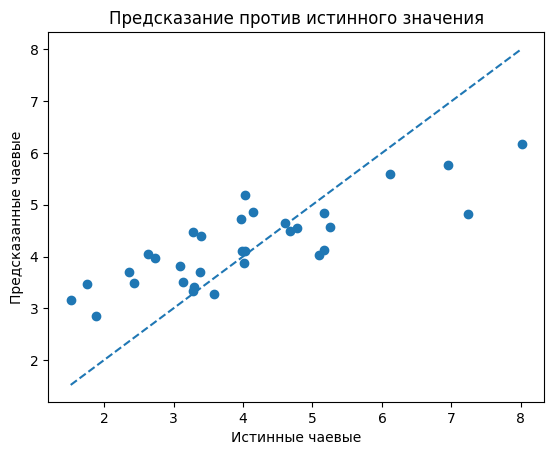

Интерпретация MAE: модель ошибается в среднем примерно на 0.81 единицы tip.


In [4]:
plt.scatter(y_test, pred)
plt.xlabel("Истинные чаевые")
plt.ylabel("Предсказанные чаевые")
plt.title("Предсказание против истинного значения")
low = min(y_test.min(), pred.min())
high = max(y_test.max(), pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.show()
print(f"Интерпретация MAE: модель ошибается в среднем примерно на {mae:.2f} единицы tip.")
